# Titanic Survival Prediction

## Problem
Build a machine learning model to predict whether a passenger survived the Titanic disaster.

## Target
Survived

## Goal
Build an end-to-end classification pipeline, compare multiple models, and evaluate the final model on unseen data.

In [1]:
from sklearn.datasets import fetch_openml

titanic = fetch_openml(
    name='titanic',
    version=1,
    as_frame=True
)

df = titanic.frame
df.head()

,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,home.dest
0,1,1,"Allen, Miss. Elisabeth Walton",female,29.0000,0,0,24160,211.3375,B5,S,2,NaN,"St Louis, MO"
1,1,1,"Allison, Master. Hudson Trevor",male,0.9167,1,2,113781,151.5500,C22 C26,S,11,NaN,"Montreal, PQ / Chesterville, ON"
2,1,0,"Allison, Miss. Helen Loraine",female,2.0000,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"
3,1,0,"Allison, Mr. Hudson Joshua Creighton",male,30.0000,1,2,113781,151.5500,C22 C26,S,NaN,135.0,"Montreal, PQ / Chesterville, ON"
4,1,0,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",female,25.0000,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"


In [2]:
df.shape

(1309, 14)

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1309 entries, 0 to 1308
Data columns (total 14 columns):
 #   Column     Non-Null Count  Dtype   
---  ------     --------------  -----   
 0   pclass     1309 non-null   int64   
 1   survived   1309 non-null   category
 2   name       1309 non-null   str     
 3   sex        1309 non-null   category
 4   age        1046 non-null   float64 
 5   sibsp      1309 non-null   int64   
 6   parch      1309 non-null   int64   
 7   ticket     1309 non-null   str     
 8   fare       1308 non-null   float64 
 9   cabin      295 non-null    str     
 10  embarked   1307 non-null   category
 11  boat       486 non-null    str     
 12  body       121 non-null    float64 
 13  home.dest  745 non-null    str     
dtypes: category(3), float64(3), int64(3), str(5)
memory usage: 116.5 KB


In [4]:
df.isna().sum()

pclass          0
survived        0
name            0
sex             0
age           263
sibsp           0
parch           0
ticket          0
fare            1
cabin        1014
embarked        2
boat          823
body         1188
home.dest     564
dtype: int64

In [5]:
df['survived'].value_counts()

survived
0    809
1    500
Name: count, dtype: int64

In [6]:
df['survived'].value_counts(normalize=True)

survived
0    0.618029
1    0.381971
Name: proportion, dtype: float64

In [7]:
features = [
    'pclass',
    'sex',
    'age',
    'sibsp',
    'parch',
    'fare',
    'embarked'
]

X = df[features]
y = df['survived']

In [8]:
numeric_features = ['pclass', 'age', 'sibsp', 'parch', 'fare']
categorical_features = ['sex', 'embarked']

In [9]:
X.isna().sum()

pclass        0
sex           0
age         263
sibsp         0
parch         0
fare          1
embarked      2
dtype: int64

In [10]:
(X.isna().mean() * 100).round(2)

pclass       0.00
sex          0.00
age         20.09
sibsp        0.00
parch        0.00
fare         0.08
embarked     0.15
dtype: float64

## Missing Values
- Age contains 20.09% of missing values.
- Fare contains 0.08%.
- Embarked contains 0.15%.

Numerical missing values will be imputed using the median.
Categorical missing values will be imputed using the most frequent value.

In [11]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

The final test set will remain untouched until model selection and hyperparameter tuning are complete.

## Modeling Plan
1. Split the data into training and final test sets.
2. Build preprocessing pipelines for numerical and categorical features.
3. Compare Logistic Regression and Random Forest using cross-validation.
4. Select an evaluation metric.
5. Tune the selected model with GridSearchCV.
6. Evaluate the final model once on the untouched test set.
7. Analyze errors and interpret the results.

In [12]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

numeric_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]
)

In [13]:
from sklearn.preprocessing import OneHotEncoder

categorical_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore'))
    ]
)

In [14]:
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

In [15]:
from sklearn.linear_model import LogisticRegression

logistic_pipeline = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('model', LogisticRegression(max_iter=1000))
    ]
)

In [16]:
from sklearn.ensemble import RandomForestClassifier

rf_pipeline = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('model', RandomForestClassifier(
            n_estimators=100,
            random_state=42
        ))
    ]
)

In [17]:
from sklearn.model_selection import cross_validate

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1"
}

In [18]:
y_train.value_counts()

survived
0    647
1    400
Name: count, dtype: int64

In [19]:
y_train = y_train.astype(int)
y_test = y_test.astype(int)

In [20]:
logistic_cv = cross_validate(
    logistic_pipeline,
    X_train,
    y_train,
    cv=5,
    scoring=scoring
)

In [21]:
rf_cv = cross_validate(
    rf_pipeline,
    X_train,
    y_train,
    cv=5,
    scoring=scoring
)

In [22]:
import pandas as pd

comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest"
    ],
    "Accuracy": [
        logistic_cv["test_accuracy"].mean(),
        rf_cv["test_accuracy"].mean()
    ],
    "Precision": [
        logistic_cv["test_precision"].mean(),
        rf_cv["test_precision"].mean()
    ],
    "Recall": [
        logistic_cv["test_recall"].mean(),
        rf_cv["test_recall"].mean()
    ],
    "F1": [
        logistic_cv["test_f1"].mean(),
        rf_cv["test_f1"].mean()
    ]
})

comparison.round(3)

,Model,Accuracy,Precision,Recall,F1
0,Logistic Regression,0.777,0.719,0.688,0.702
1,Random Forest,0.777,0.723,0.678,0.698


In [23]:
print(
    "Logistic F1:",
    logistic_cv["test_f1"].mean().round(5),
    "+/-",
    logistic_cv["test_f1"].std().round(5)
)

print(
    "Random Forest F1:",
    rf_cv["test_f1"].mean().round(5),
    "+/-",
    rf_cv["test_f1"].std().round(5)
)

Logistic F1: 0.70157 +/- 0.02376
Random Forest F1: 0.698 +/- 0.052


## Model Selection
I selected Logistic Regression because it achieved the highest mean F1 score during cross-validation.

In [24]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "model__C": [0.01, 0.1, 1, 10, 100]
}

In [25]:
grid_search = GridSearchCV(
    estimator=logistic_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1
)

In [26]:
grid_search.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step..._iter=1000))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__C': [0.01, 0.1, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with h

In [27]:
grid_search.best_params_

{'model__C': 0.1}

In [28]:
grid_search.best_score_.round(3)

np.float64(0.704)

In [29]:
import pandas as pd

results = pd.DataFrame(grid_search.cv_results_)

results[
    [
        "params",
        "mean_test_score",
        "std_test_score",
        "rank_test_score"
    ]
].sort_values("rank_test_score").head(10)

,params,mean_test_score,std_test_score,rank_test_score
1,{'model__C': 0.1},0.704247,0.032108,1
2,{'model__C': 1},0.701569,0.023765,2
3,{'model__C': 10},0.701569,0.023765,2
4,{'model__C': 100},0.701569,0.023765,2
0,{'model__C': 0.01},0.632761,0.047574,5


In [30]:
best_model = grid_search.best_estimator_

test_pred = best_model.predict(X_test)

In [31]:
import joblib

joblib.dump(best_model, "model.pkl") # saving the pipeline

['model.pkl']

In [45]:
!ls

01_model_development.ipynb model.pkl
app                        README.md


In [32]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

accuracy = accuracy_score(y_test, test_pred)
precision = precision_score(y_test, test_pred)
recall = recall_score(y_test, test_pred)
f1 = f1_score(y_test, test_pred)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1:", f1)

Accuracy: 0.8129770992366412
Precision: 0.7741935483870968
Recall: 0.72
F1: 0.7461139896373057


In [33]:
cm = confusion_matrix(y_test, test_pred)

cm

array([[141,  21],
       [ 28,  72]])

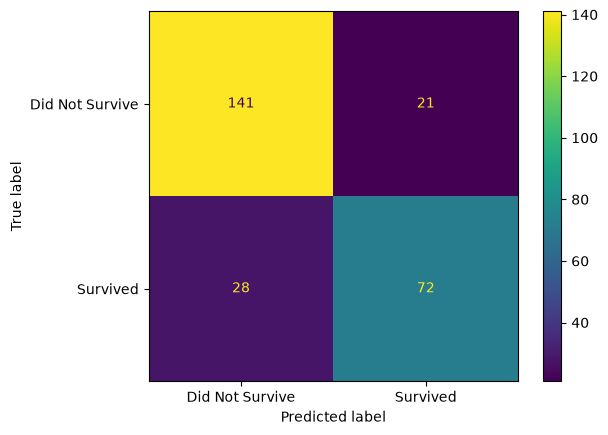

In [34]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_pred,
    display_labels=['Did Not Survive', 'Survived']
)

In [35]:
cv_f1 = grid_search.best_score_

print("Best CV F1:", cv_f1)
print("Final Test F1:", f1)
print("Difference:", abs(cv_f1 - f1))

Best CV F1: 0.7042471011670279
Final Test F1: 0.7461139896373057
Difference: 0.04186688847027775


In [36]:
error_analysis = X_test.copy()

error_analysis["actual"] = y_test.values
error_analysis["predicted"] = test_pred

The final test F1 score was slightly higher than the cross-validation F1 score, with a difference of about 0.042. This suggests that the model generalized reasonably well, although the final test set may have been slightly easier than some of the cross-validation folds.

In [37]:
errors = error_analysis[
    error_analysis["actual"] != error_analysis["predicted"]
    ]

errors.head(20)

,pclass,sex,age,sibsp,parch,fare,embarked,actual,predicted
1121,3,male,NaN,1,1,22.3583,C,1,0
20,1,male,37.0,1,1,52.5542,S,1,0
975,3,female,26.0,1,0,16.1000,S,0,1
742,3,male,45.0,0,0,8.0500,S,1,0
889,3,male,26.0,0,0,7.7750,S,1,0
596,2,male,31.0,0,0,13.0000,S,1,0
37,1,male,NaN,0,0,26.5500,S,1,0
1254,3,male,25.0,0,0,0.0000,S,1,0
136,1,male,53.0,0,0,28.5000,C,1,0
1209,3,female,2.0,3,2,27.9000,S,0,1


In [38]:
false_negatives = error_analysis[
    (error_analysis["actual"] == 1) &
    (error_analysis["predicted"] == 0)
]

false_negatives

,pclass,sex,age,sibsp,parch,fare,embarked,actual,predicted
1121,3,male,NaN,1,1,22.3583,C,1,0
20,1,male,37.0000,1,1,52.5542,S,1,0
742,3,male,45.0000,0,0,8.0500,S,1,0
889,3,male,26.0000,0,0,7.7750,S,1,0
596,2,male,31.0000,0,0,13.0000,S,1,0
37,1,male,NaN,0,0,26.5500,S,1,0
1254,3,male,25.0000,0,0,0.0000,S,1,0
136,1,male,53.0000,0,0,28.5000,C,1,0
514,2,male,2.0000,1,1,26.0000,S,1,0
656,3,female,33.0000,3,0,15.8500,S,1,0


In [39]:
false_positives = error_analysis[
    (error_analysis["actual"] == 0) &
    (error_analysis["predicted"] == 1)
]

false_positives

,pclass,sex,age,sibsp,parch,fare,embarked,actual,predicted
975,3,female,26.0,1,0,16.1000,S,0,1
1209,3,female,2.0,3,2,27.9000,S,0,1
650,3,female,17.0,0,0,14.4583,C,0,1
878,3,female,25.0,1,0,7.9250,S,0,1
749,3,female,28.0,1,1,14.4000,S,0,1
1156,3,female,2.0,1,1,20.2125,S,0,1
228,1,male,18.0,1,0,108.9000,C,0,1
1265,3,female,10.0,0,2,24.1500,S,0,1
106,1,male,NaN,0,0,221.7792,S,0,1
105,1,female,36.0,0,0,31.6792,C,0,1


In [40]:
print(len(false_negatives))
print(len(false_positives))

28
21


In [41]:
false_negatives[['sex','pclass']].value_counts()

sex     pclass
male    3         11
        1         11
        2          4
female  3          2
        1          0
        2          0
Name: count, dtype: int64

In [42]:
false_positives[['sex','pclass']].value_counts()

sex     pclass
female  3         14
male    1          5
female  1          2
male    3          0
Name: count, dtype: int64

In [43]:
false_negatives['sex'].value_counts(normalize=True)

sex
male      0.928571
female    0.071429
Name: proportion, dtype: float64

In [44]:
false_positives['sex'].value_counts(normalize=True)

sex
female    0.761905
male      0.238095
Name: proportion, dtype: float64

## Conclusion

- Selected model: Logistic Regression
- Best hyperparameters: 0.1
- Best CV F1: 0.704
- Final accuracy: 0.813
- Final precision: 0.774
- Final recall: 0.72
- Final F1: 0.746
- CV vs test difference: 0.042

### Error Analysis
- Number of false positives: 21
- Number of false negatives: 28
- Observations: Many false negatives were male survivors, while many false positives were female non-survivors. This suggests that the model may rely heavily on sex and struggle with passengers who do not follow the dominant survival pattern associated with their sex.